# MRI k-Space Reconstruction: From Frequency Data to Images

**A personal biomedical engineering learning project by Sivanji Alluri**

This notebook explores how an MRI image can be represented in the spatial-frequency domain (k-space), and how different acquisition conditions affect reconstruction. It uses a **synthetic 2D phantom generated in this notebook**—no patient data, course dataset, grading template, or hidden assessment cells are included.

### Experiments

1. Reconstruct an image from fully sampled, ideal k-space.
2. Add complex Gaussian noise and inspect its effect.
3. Truncate high spatial frequencies and observe loss of detail and edge ringing.
4. Undersample phase-encoding lines and observe aliasing.

The goal is to make the Fourier-transform ideas visible, not to build a clinically validated MRI reconstruction pipeline.

## 1. The basic idea

An MRI scanner does not directly measure an image. In a simplified model, spatial information is encoded as complex-valued samples in k-space.

For a two-dimensional object \(I(x,y)\), the forward and inverse Fourier transforms are

\[
K(k_x,k_y)=\mathcal{F}\{I(x,y)\}, \qquad
I(x,y)=\mathcal{F}^{-1}\{K(k_x,k_y)\}.
\]

In practice, the measured data can contain noise or have missing samples. This notebook changes the k-space data and then applies the inverse transform to see what happens in the image domain.

## 2. Imports and reproducibility

Only NumPy and Matplotlib are needed. A fixed random seed makes the noise experiment repeatable.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (7, 5)
plt.rcParams["image.cmap"] = "gray"
plt.rcParams["axes.grid"] = False

rng = np.random.default_rng(42)
N = 256

## 3. Create a synthetic 2D phantom

A phantom is a simplified object with known structure. Here, overlapping ellipses create a head-like cross-section with regions of different intensity. The pattern is deliberately synthetic and is only used to demonstrate the mathematics.

The coordinate values run from -1 to 1. The helper below draws a rotated ellipse into an image array.

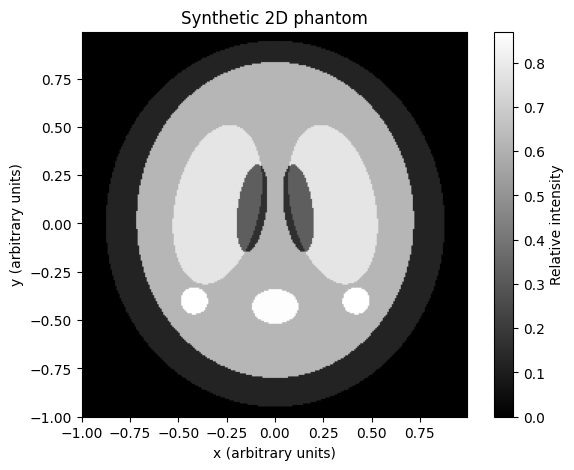

In [2]:
axis = np.linspace(-1.0, 1.0, N, endpoint=False)
X, Y = np.meshgrid(axis, axis)


def ellipse_mask(x_grid, y_grid, center, radii, angle_deg=0):
    """Return a boolean mask for a rotated ellipse."""
    cx, cy = center
    rx, ry = radii
    angle = np.deg2rad(angle_deg)
    dx = x_grid - cx
    dy = y_grid - cy
    x_rot = dx * np.cos(angle) + dy * np.sin(angle)
    y_rot = -dx * np.sin(angle) + dy * np.cos(angle)
    return (x_rot / rx) ** 2 + (y_rot / ry) ** 2 <= 1


phantom = np.zeros((N, N), dtype=float)
phantom[ellipse_mask(X, Y, (0.0, 0.0), (0.88, 0.95))] = 0.12
phantom[ellipse_mask(X, Y, (0.0, 0.02), (0.72, 0.82))] = 0.62

# Internal regions and small inclusions
phantom[ellipse_mask(X, Y, (-0.30, 0.10), (0.22, 0.42), -12)] += 0.16
phantom[ellipse_mask(X, Y, (0.30, 0.10), (0.22, 0.42), 12)] += 0.16
phantom[ellipse_mask(X, Y, (-0.12, 0.08), (0.075, 0.23), -8)] -= 0.46
phantom[ellipse_mask(X, Y, (0.12, 0.08), (0.075, 0.23), 8)] -= 0.46
phantom[ellipse_mask(X, Y, (0.0, -0.43), (0.12, 0.09), 0)] += 0.24
phantom[ellipse_mask(X, Y, (-0.42, -0.40), (0.07, 0.07), 0)] += 0.25
phantom[ellipse_mask(X, Y, (0.42, -0.40), (0.07, 0.07), 0)] += 0.25
phantom = np.clip(phantom, 0.0, 1.0)

fig, ax = plt.subplots()
im = ax.imshow(phantom, extent=[axis[0], axis[-1], axis[0], axis[-1]], origin="lower")
ax.set(title="Synthetic 2D phantom", xlabel="x (arbitrary units)", ylabel="y (arbitrary units)")
fig.colorbar(im, ax=ax, label="Relative intensity")
plt.show()

## 4. Transform the phantom into k-space

`fft2` calculates the two-dimensional discrete Fourier transform. `fftshift` moves the zero-frequency component to the centre of the display, which makes the low-frequency region easier to identify.

The inverse operation reverses those steps. For a fully sampled dataset, the reconstructed image should match the phantom up to floating-point precision.

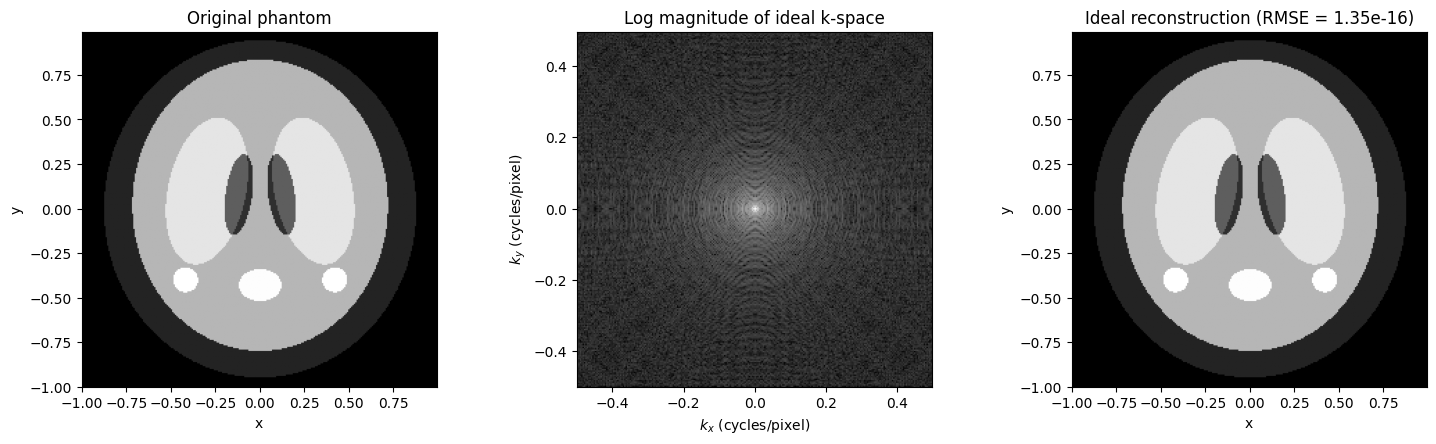

Ideal reconstruction RMSE: 1.347e-16


In [3]:
def image_to_kspace(image):
    """Compute centred 2D k-space from an image."""
    return np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(image)))


def kspace_to_image(kspace):
    """Reconstruct a magnitude image from centred 2D k-space."""
    complex_image = np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(kspace)))
    return np.abs(complex_image)


def rmse(reference, reconstruction):
    """Root mean square error between two arrays of the same shape."""
    return float(np.sqrt(np.mean((reference - reconstruction) ** 2)))


kspace_ideal = image_to_kspace(phantom)
reconstruction_ideal = kspace_to_image(kspace_ideal)
rmse_ideal = rmse(phantom, reconstruction_ideal)

frequency = np.fft.fftshift(np.fft.fftfreq(N, d=1.0))  # cycles per pixel
extent_k = [frequency[0], frequency[-1], frequency[0], frequency[-1]]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].imshow(phantom, extent=[axis[0], axis[-1], axis[0], axis[-1]], origin="lower")
axes[0].set(title="Original phantom", xlabel="x", ylabel="y")
axes[1].imshow(np.log1p(np.abs(kspace_ideal)), extent=extent_k, origin="lower")
axes[1].set(title="Log magnitude of ideal k-space", xlabel="$k_x$ (cycles/pixel)", ylabel="$k_y$ (cycles/pixel)")
axes[2].imshow(reconstruction_ideal, extent=[axis[0], axis[-1], axis[0], axis[-1]], origin="lower")
axes[2].set(title=f"Ideal reconstruction (RMSE = {rmse_ideal:.2e})", xlabel="x", ylabel="y")
plt.tight_layout()
plt.show()
print(f"Ideal reconstruction RMSE: {rmse_ideal:.3e}")

## 5. Add complex-valued measurement noise

A simple model for thermal receiver noise is complex Gaussian noise. Independent noise is added to the real and imaginary parts of k-space:

\[
K_{\mathrm{noisy}}=K_{\mathrm{ideal}}+n_r+i n_i.
\]

This is a simplified white-noise model. Real scanner data can also have spatially or channel-correlated noise, especially in multi-coil acquisitions.

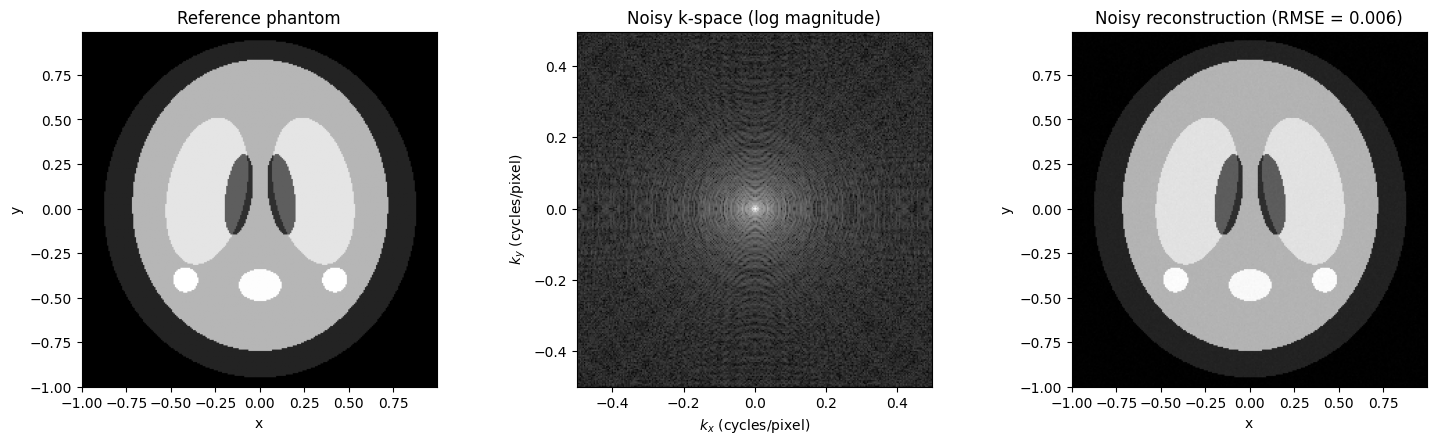

Noisy reconstruction RMSE: 0.0056


In [4]:
noise_level = 0.015 * np.sqrt(np.mean(np.abs(kspace_ideal) ** 2))
noise = (noise_level / np.sqrt(2)) * (
    rng.standard_normal(kspace_ideal.shape)
    + 1j * rng.standard_normal(kspace_ideal.shape)
)

kspace_noisy = kspace_ideal + noise
reconstruction_noisy = kspace_to_image(kspace_noisy)
rmse_noisy = rmse(phantom, reconstruction_noisy)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].imshow(phantom, extent=[axis[0], axis[-1], axis[0], axis[-1]], origin="lower")
axes[0].set(title="Reference phantom", xlabel="x", ylabel="y")
axes[1].imshow(np.log1p(np.abs(kspace_noisy)), extent=extent_k, origin="lower")
axes[1].set(title="Noisy k-space (log magnitude)", xlabel="$k_x$ (cycles/pixel)", ylabel="$k_y$ (cycles/pixel)")
axes[2].imshow(reconstruction_noisy, extent=[axis[0], axis[-1], axis[0], axis[-1]], origin="lower")
axes[2].set(title=f"Noisy reconstruction (RMSE = {rmse_noisy:.3f})", xlabel="x", ylabel="y")
plt.tight_layout()
plt.show()
print(f"Noisy reconstruction RMSE: {rmse_noisy:.4f}")

### Note: white noise versus coloured noise

White noise has approximately equal power across frequencies and, in the simplest model, independent samples. Coloured noise has a frequency-dependent spectrum or correlations between samples. In MRI, receiver bandwidth and filtering, electromagnetic interference, and correlations between receive coils can make the noise depart from the ideal white-noise model. Reconstruction operations can also introduce correlations.

Coloured noise may appear as structured or non-uniform noise in the image instead of uniform grain. Possible responses include measuring noise covariance, pre-whitening multi-coil data, correcting hardware interference, and using noise-aware reconstruction. Filtering can reduce noise but may also remove useful high-frequency detail.

## 6. Truncate high spatial frequencies

High spatial frequencies encode fine details and sharp transitions. Here, only a central square of k-space is retained; everything outside the cutoff is set to zero. This is a simple model of limited spatial-frequency coverage. The cutoff is expressed in cycles per pixel.

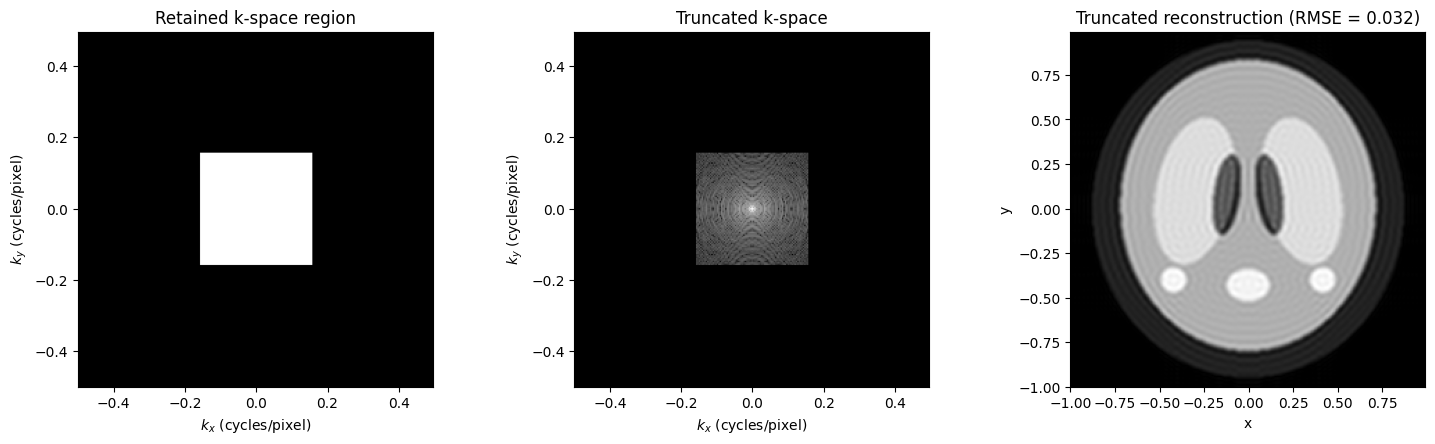

Truncated reconstruction RMSE: 0.0324


In [5]:
cutoff = 0.16  # cycles per pixel
KX, KY = np.meshgrid(frequency, frequency)
central_mask = (np.abs(KX) <= cutoff) & (np.abs(KY) <= cutoff)
kspace_truncated = kspace_ideal * central_mask
reconstruction_truncated = kspace_to_image(kspace_truncated)
rmse_truncated = rmse(phantom, reconstruction_truncated)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].imshow(central_mask, extent=extent_k, origin="lower")
axes[0].set(title="Retained k-space region", xlabel="$k_x$ (cycles/pixel)", ylabel="$k_y$ (cycles/pixel)")
axes[1].imshow(np.log1p(np.abs(kspace_truncated)), extent=extent_k, origin="lower")
axes[1].set(title="Truncated k-space", xlabel="$k_x$ (cycles/pixel)", ylabel="$k_y$ (cycles/pixel)")
axes[2].imshow(reconstruction_truncated, extent=[axis[0], axis[-1], axis[0], axis[-1]], origin="lower")
axes[2].set(title=f"Truncated reconstruction (RMSE = {rmse_truncated:.3f})", xlabel="x", ylabel="y")
plt.tight_layout()
plt.show()
print(f"Truncated reconstruction RMSE: {rmse_truncated:.4f}")

### Why does truncation blur edges and cause ringing?

Truncating k-space multiplies the full spectrum by a rectangular window. Multiplication in the frequency domain corresponds to convolution in the image domain. The inverse Fourier transform of a sharp rectangular cutoff has a sinc-like response, so the reconstructed image is blurred and can show oscillations near sharp boundaries. These edge oscillations are commonly called **Gibbs ringing**.

A smoother k-space window (apodization), such as a Hamming or Tukey window, can reduce ringing. The trade-off is additional smoothing and some loss of spatial resolution. Acquiring more high-frequency data is the direct way to preserve fine detail.

## 7. Undersample the phase-encoding direction

In Cartesian MRI, one common acquisition pattern samples complete readout lines but skips some phase-encoding lines. Here, every second row of the centred k-space array is retained. The missing rows are set to zero before the inverse transform.

The factor of two below compensates for the fact that only half of the k-space lines were retained. It restores approximate intensity scaling; it does **not** remove the aliasing.

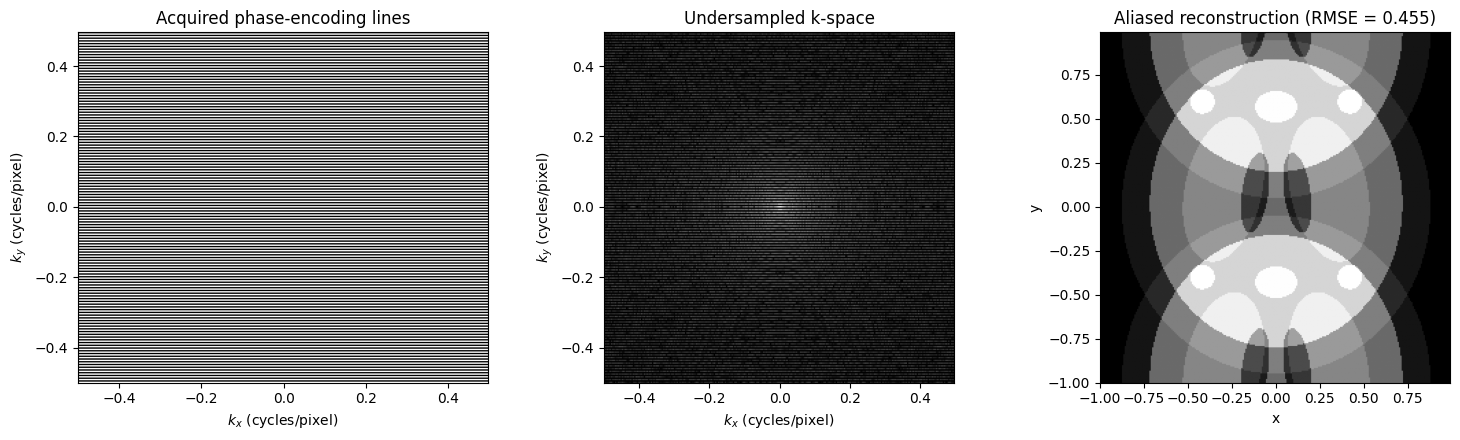

Undersampled reconstruction RMSE: 0.4550


In [6]:
acceleration = 2
sampling_mask = np.zeros(kspace_ideal.shape, dtype=bool)
sampling_mask[::acceleration, :] = True
kspace_undersampled = np.where(sampling_mask, kspace_ideal, 0)
reconstruction_undersampled = acceleration * kspace_to_image(kspace_undersampled)
rmse_undersampled = rmse(phantom, reconstruction_undersampled)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].imshow(sampling_mask, extent=extent_k, origin="lower", aspect="auto")
axes[0].set(title="Acquired phase-encoding lines", xlabel="$k_x$ (cycles/pixel)", ylabel="$k_y$ (cycles/pixel)")
axes[1].imshow(np.log1p(np.abs(kspace_undersampled)), extent=extent_k, origin="lower")
axes[1].set(title="Undersampled k-space", xlabel="$k_x$ (cycles/pixel)", ylabel="$k_y$ (cycles/pixel)")
axes[2].imshow(reconstruction_undersampled, extent=[axis[0], axis[-1], axis[0], axis[-1]], origin="lower")
axes[2].set(title=f"Aliased reconstruction (RMSE = {rmse_undersampled:.3f})", xlabel="x", ylabel="y")
plt.tight_layout()
plt.show()
print(f"Undersampled reconstruction RMSE: {rmse_undersampled:.4f}")

### Why does undersampling cause aliasing?

Uniformly skipping phase-encoding lines increases the spacing between acquired k-space samples. In the image domain, this produces repeated copies of the object that can overlap (wrap-around or aliasing). The exact direction of the fold-over depends on which k-space direction is undersampled.

Parallel imaging methods use information from multiple receiver coils to help separate these overlapping signals. Two well-known examples are:

- **SENSE**: uses coil sensitivity maps and solves an unfolding problem in the image domain.
- **GRAPPA**: uses calibration data and neighbouring multi-coil k-space samples to estimate missing k-space lines.

These methods trade scan acceleration against noise amplification and reconstruction sensitivity. The simulation here shows aliasing only; it does not implement SENSE or GRAPPA.

## 8. Compare the reconstruction errors

RMSE is a compact numerical comparison, but it does not describe every visual artifact. Always inspect the images as well as the metric.

       Ideal: RMSE = 0.00000
       Noisy: RMSE = 0.00562
   Truncated: RMSE = 0.03238
Undersampled: RMSE = 0.45496


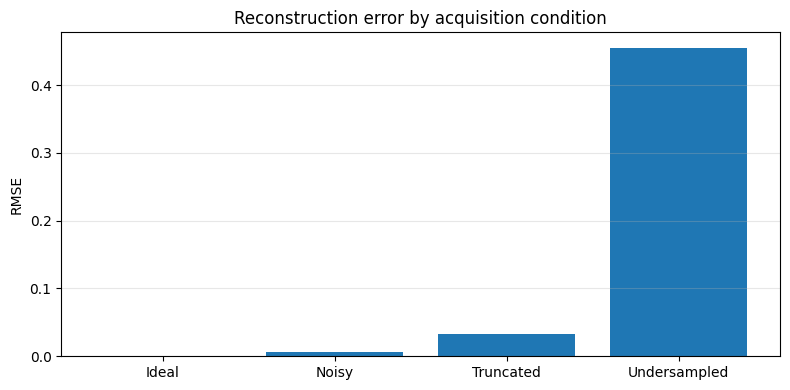

In [7]:
results = {
    "Ideal": rmse_ideal,
    "Noisy": rmse_noisy,
    "Truncated": rmse_truncated,
    "Undersampled": rmse_undersampled,
}

for experiment, value in results.items():
    print(f"{experiment:>12}: RMSE = {value:.5f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(list(results.keys()), list(results.values()))
ax.set(title="Reconstruction error by acquisition condition", ylabel="RMSE")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Key takeaways and limitations

- With complete, noiseless k-space, the inverse Fourier transform recovers the synthetic phantom to numerical precision.
- Complex measurement noise reduces image quality and increases RMSE.
- Removing high spatial frequencies smooths fine structure and can cause Gibbs ringing near sharp edges.
- Skipping phase-encoding lines creates fold-over aliasing; intensity rescaling alone does not solve it.
- SENSE and GRAPPA are important parallel-imaging strategies, but neither is implemented in this demonstration.

**Limitations:** This is a two-dimensional educational simulation with a synthetic object and simplified noise. It does not model gradient imperfections, relaxation, coil sensitivities, trajectory errors, non-Cartesian sampling, or clinical image reconstruction. It must not be used for diagnosis or treatment planning.